**IMPLEMENTACIÓN SEGUNDA ENTREGA**

**IMPLEMENTACIÓN MODELO YOLO26m PARA DETECCIÓN**

**IMPORTACIÓN LIBRERIAS**

In [1]:
from ultralytics import YOLO

In [2]:
import seaborn as sns
import matplotlib.pyplot as plt

In [3]:
import numpy as np
import pandas as pd
import json

In [57]:
from tqdm import tqdm
import os
from pathlib import Path
from PIL import Image
import time
from IPython.display import clear_output

**IMPORTACIÓN MODELO YOLO26m**

In [5]:
model_26m = YOLO('yolo26m.pt')

**IMPLEMENTACIÓN DE FUNCIÓN PARA PREDICCIÓN DE FONDO EN IMAGENES**

In [ ]:
def detectar_fotos(model, carpeta_imgs, carpeta_labels, conf_min=0.1,
                   clase=15, batch=16, salida=None):

    #LECTURA DE CONJUNTO DE IMAGENES Y LABELS DE PRUEBA
    carpeta_imgs, carpeta_labels = Path(carpeta_imgs), Path(carpeta_labels)
    imgs = sorted(carpeta_imgs.glob('*.jpg'))
    filas = []

    #DETECCIÓN DE FONDO EN IMAGENES POR LOTEs
    for i in tqdm(range(0, len(imgs), batch)):
        lote = imgs[i:i + batch]

        #DETECCIÓN DE FONDO EN IMAGENES INDIVIDUALES
        res = model.predict(source=[str(p) for p in lote], conf=conf_min,
                            classes=[clase], device=0, verbose=False, save=False)
        for p, r in zip(lote, res):
            txt = carpeta_labels / (p.stem + '.txt')
            n_real = 0
            if txt.exists():
                n_real = sum(1 for l in txt.read_text().splitlines()
                             if l.split() and l.split()[0] == str(clase))
                
            #REPORTE DE BOXES POR NIVEL DE CONFIANZA Y CANTIDAD DE FELINOS REALES POR IMAGEN
            filas.append({'foto': p.name,
                          'n_real': n_real,
                          'confs': r.boxes.conf.cpu().numpy().tolist()})

    df = pd.DataFrame(filas)
    if salida:
        df.to_pickle(salida)  
    return df

In [ ]:
#DETECTECCIÓN DE IMAGENES DE VALIDACIÓN COCO2017
df_det_coco = detectar_fotos(
    model_26m,
    carpeta_imgs=r'../data/external/val2017/images',
    carpeta_labels=r'../data/external/val2017/labels',
    conf_min=0.10,
    salida=r'../outputs/detector/det_coco_yolo26m.pkl'
)

100%|██████████| 313/313 [06:21<00:00,  1.22s/it]


**EVALUACIÓN DE YOLO26m POR NIVELES DE CONFIANZA**

In [ ]:
def evaluar_umbrales(df, umbrales=(0.10, 0.25, 0.40, 0.50, 0.70)):
    hay_gato = df['n_real'] >= 1
    filas = []

    #EVALUACIÓN DE DETECCIÓN POR UMBRALES
    for t in tqdm(umbrales, total=len(umbrales)):

        #FILTRADO DE DETECCIONES TOTALES POR UMBRAL
        n_det = df['confs'].apply(lambda c: sum(x >= t for x in c))
        pred = n_det >= 1

        #METRICAS DE EVALUACIÓN DE DETECCIONES
        tp = int((pred & hay_gato).sum())
        fp = int((pred & ~hay_gato).sum())
        fn = int((~pred & hay_gato).sum())
        tn = int((~pred & ~hay_gato).sum())

        precision = tp / (tp + fp) if (tp + fp) else 0
        recall = tp / (tp + fn) if (tp + fn) else 0
        f1 = 2 * precision * recall / (precision + recall) if (precision + recall) else 0

        #REPORTE METRICAS
        filas.append({'conf': t, 'TP': tp, 'FP': fp, 'FN': fn, 'TN': tn,
                      'precision': round(precision, 3),
                      'recall': round(recall, 3),
                      'f1': round(f1, 3),
                      'fotos_0_gatos': int((n_det == 0).sum()),
                      'fotos_1_gato': int((n_det == 1).sum()),
                      'fotos_2_o_mas': int((n_det >= 2).sum())})

    return pd.DataFrame(filas)

In [ ]:
#REPORTE DE METRICAS POR UMBRALES DE CONFIANZA COCO2017
tabla_eval_coco = evaluar_umbrales(df_det_coco) 
tabla_eval_coco.to_csv(r'../outputs/detector/umbrales_coco_yolo26m.csv', index=False)
tabla_eval_coco

100%|██████████| 5/5 [00:00<00:00, 215.87it/s]


,conf,TP,FP,FN,TN,precision,recall,f1,fotos_0_gatos,fotos_1_gato,fotos_2_o_mas
0,0.10,177,11,7,4805,0.941,0.962,0.952,4812,154,34
1,0.25,173,4,11,4812,0.977,0.940,0.958,4823,155,22
2,0.40,169,2,15,4814,0.988,0.918,0.952,4829,154,17
3,0.50,166,2,18,4814,0.988,0.902,0.943,4832,151,17
4,0.70,155,0,29,4816,1.000,0.842,0.914,4845,142,13


In [ ]:
#VALIDACIÓN DE METRICAS YOLO26m VALIDACIÓN COCO2017
metrics_coco_val = model_26m.val(
        data='../data/external/coco.yaml', 
        save=False,
        save_json=True,
        conf=0.25,
        classes=[15],
        device=0, 
        verbose=False,
        plots=True
    )

Ultralytics 8.4.176  Python-3.12.10 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 2050, 4096MiB)
YOLO26m summary (fused): 130 layers, 20,411,132 parameters, 0 gradients, 68.4 GFLOPs
val: Fast image access  (ping: 0.0±0.0 ms, read: 1119.2±479.1 MB/s, size: 147.9 KB)
val: Scanning C:\Users\castr\OneDrive\Desktop\proyecto_ia\data\external\val2017\labels.cache... 4952 images, 48 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 5000/5000  0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 313/313 1.3it/s 3:520.5ss4
                   all       5000        202      0.942      0.891      0.895      0.759
Speed: 1.0ms preprocess, 37.1ms inference, 0.0ms loss, 1.3ms postprocess per image
Saving C:\Users\castr\OneDrive\Desktop\proyecto_ia\notebooks\runs\detect\val\predictions.json...

Evaluating faster-coco-eval mAP...
Evaluate annotation type *bbox*
COCOeval_opt.evaluate() finished...
DONE (t=0.98s).
Accumulating evaluation results...
COCOe

In [ ]:
#GUARDADO DE METRICAS YOLO26m COCO2017
np.save("../outputs/detector/cm_coco.npy", metrics_coco_val.confusion_matrix.matrix)
np.save("../outputs/detector/ap_coco_por_clase.npy", metrics_coco_val.box.maps)
with open("../outputs/detector/metricas_coco.json", "w") as f:
    json.dump(metrics_coco_val.results_dict, f, indent=2)

In [12]:
print("mAP50-95:", metrics_coco_val.box.map, "| mAP50:", metrics_coco_val.box.map50)
print("AP del gato:", metrics_coco_val.box.maps[15])

mAP50-95: 0.7594675910533589 | mAP50: 0.8947665818533242
AP del gato: 0.7594675910533589


In [13]:
cm_coco_val = np.load("../outputs/detector/cm_coco.npy")
maps_coco_val = np.load("../outputs/detector/ap_coco_por_clase.npy")
with open("../outputs/detector/metricas_coco.json") as f:
    res_coco_val = json.load(f)

**VALIDACIÓN MUESTRA 300**

In [ ]:
#DETECTECCIÓN DE IMAGENES DE VALIDACIÓN Cat-Dataset
df_det_muestra_300 = detectar_fotos(
    model_26m,
    carpeta_imgs=r'../data/external/muestra_300/images',
    carpeta_labels=r'../data/external/muestra_300/labels',
    conf_min=0.10,
    salida=r'../outputs/detector/det_muestra_300_yolo26m.pkl'
)

100%|██████████| 19/19 [00:14<00:00,  1.32it/s]


In [ ]:
#REPORTE DE METRICAS POR UMBRALES DE CONFIANZA COCO2017
tabla_eval_muestra_300 = evaluar_umbrales(df_det_muestra_300) 
tabla_eval_muestra_300.to_csv(r'../outputs/detector/umbrales_muestra_300_yolo26m.csv', index=False)
tabla_eval_muestra_300

100%|██████████| 5/5 [00:00<00:00, 779.06it/s]


,conf,TP,FP,FN,TN,precision,recall,f1,fotos_0_gatos,fotos_1_gato,fotos_2_o_mas
0,0.10,299,0,1,0,1.0,0.997,0.998,1,278,21
1,0.25,299,0,1,0,1.0,0.997,0.998,1,290,9
2,0.40,299,0,1,0,1.0,0.997,0.998,1,293,6
3,0.50,299,0,1,0,1.0,0.997,0.998,1,293,6
4,0.70,292,0,8,0,1.0,0.973,0.986,8,287,5


In [ ]:
#VALIDACIÓN DE METRICAS YOLO26m VALIDACIÓN Cat-Dataset
metrics_muestra_300 = model_26m.val(
    data="../data/external/muestra_300.yaml", 
    conf=0.25,
    save=False,
    device='cpu', 
    verbose=False,
    plots=True
)

Ultralytics 8.4.176  Python-3.12.10 torch-2.11.0+cu128 CPU (12th Gen Intel Core i5-12450H)
YOLO26m summary (fused): 130 layers, 20,411,132 parameters, 0 gradients, 68.4 GFLOPs
val: Fast image access  (ping: 0.0±0.0 ms, read: 995.3±545.5 MB/s, size: 249.8 KB)
val: Scanning C:\Users\castr\OneDrive\Desktop\proyecto_ia\data\external\muestra_300\labels.cache... 300 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 300/300  0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 19/19 5.1s/it 1:375.2sss
                   all        300        307       0.99      0.983      0.983      0.844
Speed: 0.5ms preprocess, 314.7ms inference, 0.0ms loss, 0.8ms postprocess per image
Results saved to C:\Users\castr\OneDrive\Desktop\proyecto_ia\notebooks\runs\detect\val-2


In [ ]:
#GUARDADO DE METRICAS YOLO26m Cat-Dataset
np.save("../outputs/detector/cm_muestra_300.npy", metrics_muestra_300.confusion_matrix.matrix)
np.save("../outputs/detector/ap_por_clase_muestra_300.npy", metrics_muestra_300.box.maps)
with open("../outputs/detector/metricas_muestra_300.json", "w") as f:
    json.dump(metrics_muestra_300.results_dict, f, indent=2)

In [18]:
print("mAP50-95:", metrics_muestra_300.box.map, "| mAP50:", metrics_muestra_300.box.map50)
print("AP del gato:", metrics_muestra_300.box.maps[15])

mAP50-95: 0.8438700693969337 | mAP50: 0.9830114704375188
AP del gato: 0.8438700693969337


In [19]:
cm_muestra_300 = np.load("../outputs/detector/cm_muestra_300.npy")
maps_muestra_300 = np.load("../outputs/detector/ap_por_clase_muestra_300.npy")
with open("../outputs/detector/metricas_muestra_300.json") as f:
    res = json.load(f)

**ANALISIS RECORTE IMAGENES REID**

In [20]:
df_reid = pd.read_csv('../data/processed/df_cat_reid.csv')
df_reid_modified = df_reid.copy()

**VALIDACIÓN CANTIDAD DE REGISTROS EN EL DATASET ORIGINAL**

In [21]:
len(df_reid_modified)

13106

In [22]:
df_reid_modified.head()

,file_path,dir_name,file_name,format,resolution,ratio,mode,file_size_mb,brightness
0,../data/interim/reid_cat/0001/0001_000.JPG,1,0001_000,JPEG,7990272,1.33,RGB,0.795949,76.44
1,../data/interim/reid_cat/0001/0001_001.JPG,1,0001_001,JPEG,7990272,1.33,RGB,0.730849,70.42
2,../data/interim/reid_cat/0001/0001_002.JPG,1,0001_002,JPEG,7990272,1.33,RGB,0.748957,112.99
3,../data/interim/reid_cat/0001/0001_003.JPG,1,0001_003,JPEG,7990272,1.33,RGB,0.795803,120.14
4,../data/interim/reid_cat/0001/0001_004.JPG,1,0001_004,JPEG,7990272,1.33,RGB,0.753259,119.54


In [ ]:
#EXTRACCIÓN DE RUTAS DE LAS IMAGENES
rutas = df_reid_modified['file_path'].astype(str).tolist()

#RUTAS PARA EL GUARDADO DE LAS DETECCIONES
PROC_DET = str("../data/interim/")
LABELS_DET = "det_26m"
lote = 32

In [ ]:
#DETECCION DE GATOS EN LAS IMAGENES
#POR LOTES DE TAMAÑO 32
#CON UNA CONFIANZA DE DETECCION DEL 0.25
#PARA LA CLASE 15 (CATS)
#EN LA CARPETA runs/data/interim/det_26m

for r in range(0, len(rutas), lote): 
    results_test_crop = model_26m.predict(
    source=rutas[r:r+lote], save=False, save_txt=True, save_conf=True, 
    classes=[15], exist_ok=True, conf=0.25,
    verbose=False, project=PROC_DET, name=LABELS_DET,
    device=0
)

Results saved to C:\Users\castr\OneDrive\Desktop\proyecto_ia\notebooks\runs\data\interim\det_26m
3826 labels saved to C:\Users\castr\OneDrive\Desktop\proyecto_ia\notebooks\runs\data\interim\det_26m\labels
Results saved to C:\Users\castr\OneDrive\Desktop\proyecto_ia\notebooks\runs\data\interim\det_26m
3826 labels saved to C:\Users\castr\OneDrive\Desktop\proyecto_ia\notebooks\runs\data\interim\det_26m\labels
Results saved to C:\Users\castr\OneDrive\Desktop\proyecto_ia\notebooks\runs\data\interim\det_26m
3826 labels saved to C:\Users\castr\OneDrive\Desktop\proyecto_ia\notebooks\runs\data\interim\det_26m\labels
Results saved to C:\Users\castr\OneDrive\Desktop\proyecto_ia\notebooks\runs\data\interim\det_26m
3826 labels saved to C:\Users\castr\OneDrive\Desktop\proyecto_ia\notebooks\runs\data\interim\det_26m\labels
Results saved to C:\Users\castr\OneDrive\Desktop\proyecto_ia\notebooks\runs\data\interim\det_26m
3826 labels saved to C:\Users\castr\OneDrive\Desktop\proyecto_ia\notebooks\runs\dat

In [ ]:
#LECTURA DE LABELS POR DETECCION DE GATOS
PATH_LABELS = "./runs/data/interim/det_26m/labels"
labels = [os.path.basename(f).split('.')[0] for f in os.scandir(PATH_LABELS) if os.path.basename(f).endswith('txt')]
cat_images = df_reid_modified['file_name'].tolist()

In [48]:
df_analysis = df_reid_modified.copy()

df_analysis['detected'] = df_analysis['file_name'].isin(labels).astype(int)

**REPORTE DE DETECCIONES DE GATOS,**
**DONDE NO SE PERMITE LA PRESENCIA DE UNA IMAGEN**
**CON MAS DE DOS DETECCIONES**

In [49]:
for id in tqdm(labels):
    file_name = f'{id}.txt'
    file_path = f'{PATH_LABELS}/{file_name}'
    try: 
        data = np.loadtxt(file_path)

        if data.size > 0:
            if data.ndim == 1:
                conf_prediction = data[-1]
            else:
                conf_prediction = 0.0
        else:
            conf_prediction = 0.0
    except Exception:
        conf_prediction = 0.0
    df_analysis.loc[df_analysis['file_name'] == id, 'conf'] = conf_prediction

100%|██████████| 12872/12872 [04:01<00:00, 53.40it/s] 


In [50]:
df_analysis.head()

,file_path,dir_name,file_name,format,resolution,ratio,mode,file_size_mb,brightness,detected,conf
0,../data/interim/reid_cat/0001/0001_000.JPG,1,0001_000,JPEG,7990272,1.33,RGB,0.795949,76.44,1,0.938533
1,../data/interim/reid_cat/0001/0001_001.JPG,1,0001_001,JPEG,7990272,1.33,RGB,0.730849,70.42,1,0.956267
2,../data/interim/reid_cat/0001/0001_002.JPG,1,0001_002,JPEG,7990272,1.33,RGB,0.748957,112.99,1,0.941518
3,../data/interim/reid_cat/0001/0001_003.JPG,1,0001_003,JPEG,7990272,1.33,RGB,0.795803,120.14,1,0.935277
4,../data/interim/reid_cat/0001/0001_004.JPG,1,0001_004,JPEG,7990272,1.33,RGB,0.753259,119.54,1,0.928933


**DATASET DE REPORTE DE RUTA DE IMAGENES CON 1 DETECCIÓN**

In [51]:
df_analysis_to_save = df_analysis.loc[
    df_analysis['detected'] == 1, ['file_path', 'dir_name', 'file_name']]
df_analysis_to_save.to_csv(
    '../data/processed/df_cat_reid_validation.csv', index=False
)

**DATASET DE REPORTE DE IMAGENES CON 0 DETECCIONES O MAS DE UNA**

In [52]:
df_analysis_undetected = df_analysis.loc[
    df_analysis['detected'] == 0, ['file_path', 'dir_name', 'file_name'] 
]
df_analysis_undetected.to_csv(
    '../data/processed/df_cat_undetecteds.csv', index=False
)

Lote 11


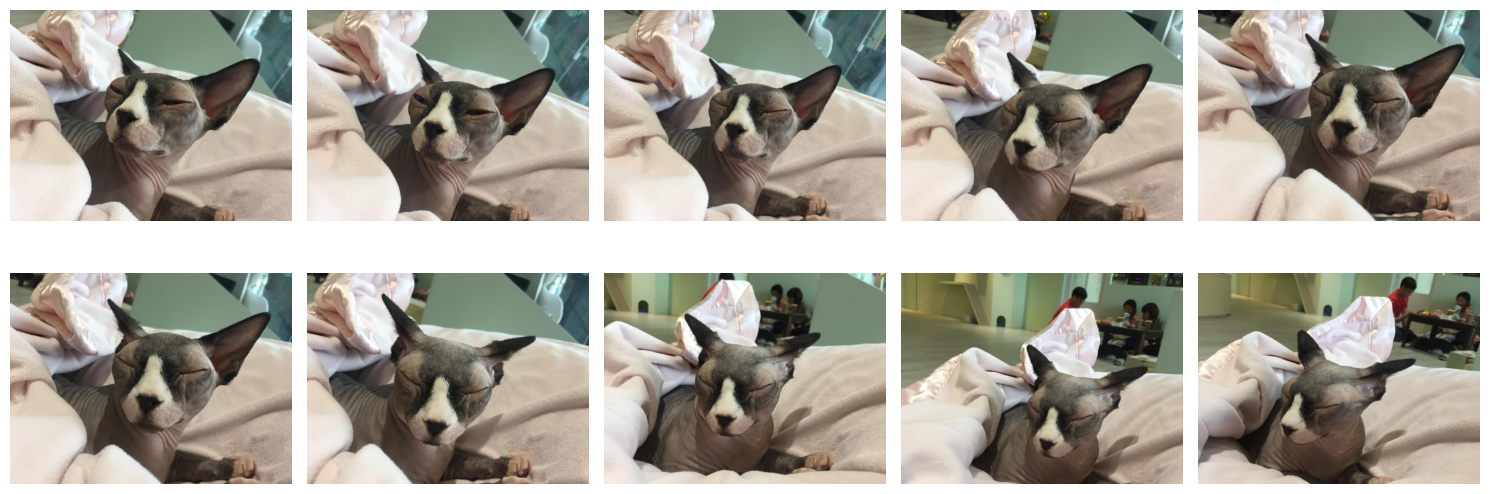

KeyboardInterrupt: 

In [67]:
for i in range(0, len(df_analysis_undetected), 10):
    clear_output(wait=True)
    print(f"Lote {i//10 + 1}")
    sub = df_analysis_undetected.iloc[i:i+10]

    plt.figure(figsize=(15, 6))
    for j, (_, row) in enumerate(sub.iterrows()):
        plt.subplot(2, 5, j + 1)
        plt.imshow(Image.open(row['file_path']))
        plt.axis('off')

    plt.tight_layout()
    plt.show()
    time.sleep(3)